In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Enable it under Runtime → Change runtime type.")

PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [2]:
!pip install -q gdown

In [3]:
import os

PROJECT_DIR = "/content/VisDrone_Project"
DOWNLOAD_DIR = os.path.join(PROJECT_DIR, "downloads")

os.makedirs(DOWNLOAD_DIR, exist_ok=True)

print("Download folder created:", DOWNLOAD_DIR)

Download folder created: /content/VisDrone_Project/downloads


In [4]:
!gdown --id 1a2oHjcEcwXP8oUF95qiwrqzACb2YlUhn -O /content/VisDrone_Project/downloads/train.zip

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1a2oHjcEcwXP8oUF95qiwrqzACb2YlUhn
From (redirected): https://drive.google.com/uc?id=1a2oHjcEcwXP8oUF95qiwrqzACb2YlUhn&confirm=t&uuid=103c155e-569b-4a0c-ad50-9d1571e0f1d9
To: /content/VisDrone_Project/downloads/train.zip
100% 1.55G/1.55G [00:20<00:00, 76.6MB/s]


In [5]:
!gdown --id 1bxK5zgLn0_L8x276eKkuYA_FzwCIjb59 -O /content/VisDrone_Project/downloads/val.zip

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1bxK5zgLn0_L8x276eKkuYA_FzwCIjb59
From (redirected): https://drive.google.com/uc?id=1bxK5zgLn0_L8x276eKkuYA_FzwCIjb59&confirm=t&uuid=9486315a-42bd-45d7-85a4-d6bdbc63a590
To: /content/VisDrone_Project/downloads/val.zip
100% 81.6M/81.6M [00:01<00:00, 81.4MB/s]


In [6]:
import os

for name in ["train.zip", "val.zip"]:
    path = os.path.join(DOWNLOAD_DIR, name)

    if os.path.exists(path):
        print(name, round(os.path.getsize(path) / (1024**3), 3), "GB")
    else:
        print(name, "NOT FOUND")


train.zip 1.443 GB
val.zip 0.076 GB


In [7]:
import zipfile
import os

RAW_DIR = "/content/VisDrone_Project/raw"
os.makedirs(RAW_DIR, exist_ok=True)

train_zip = "/content/VisDrone_Project/downloads/train.zip"
val_zip = "/content/VisDrone_Project/downloads/val.zip"

with zipfile.ZipFile(train_zip, "r") as zip_ref:
    zip_ref.extractall(RAW_DIR)

print("Training dataset extracted!")

with zipfile.ZipFile(val_zip, "r") as zip_ref:
    zip_ref.extractall(RAW_DIR)

print("Validation dataset extracted!")

Training dataset extracted!
Validation dataset extracted!


In [8]:
import os

for root, dirs, files in os.walk(RAW_DIR):
    level = root.replace(RAW_DIR, "").count(os.sep)

    if level <= 3:
        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:5]:
            print(f"{indent}    {file}")

        if len(files) > 5:
            print(f"{indent}    ... and {len(files)-5} more files")

raw/
    VisDrone2019-DET-val/
        .DS_Store
        annotations/
            0000244_00500_d_0000002.txt
            0000289_03801_d_0000830.txt
            0000280_01401_d_0000619.txt
            0000263_02401_d_0000179.txt
            0000330_00401_d_0000802.txt
            ... and 543 more files
        images/
            0000277_04601_d_0000561.jpg
            0000213_04998_d_0000245.jpg
            0000276_00001_d_0000507.jpg
            0000364_01177_d_0000799.jpg
            0000271_05401_d_0000399.jpg
            ... and 543 more files
    VisDrone2019-DET-train/
        annotations/
            9999951_00000_d_0000094.txt
            9999962_00000_d_0000127.txt
            0000072_07242_d_0000011.txt
            9999990_00000_d_0000034.txt
            9999999_00073_d_0000023.txt
            ... and 6466 more files
        images/
            0000352_03529_d_0000557.jpg
            9999975_00000_d_0000032.jpg
            9999999_00402_d_0000176.jpg
            0000068_026

In [9]:
import os

sample_ann = os.path.join(
    RAW_DIR,
    "VisDrone2019-DET-train",
    "annotations",
    "0000072_07242_d_0000011.txt"
)

with open(sample_ann, "r") as file:
    for line in file.readlines()[:10]:
        print(line.strip())

144,333,119,123,1,4,0,0
403,180,75,86,1,4,0,1
375,89,67,61,1,4,0,0
219,24,76,56,1,4,0,0
352,204,24,39,1,2,0,0
348,218,33,47,1,10,0,1
326,60,43,46,1,7,0,0
347,57,10,24,1,2,0,1
721,115,122,62,1,4,0,1
768,72,51,49,1,4,0,0


In [10]:
import os

sample_ann = os.path.join(
    RAW_DIR,
    "VisDrone2019-DET-train",
    "annotations",
    "0000072_07242_d_0000011.txt"
)

with open(sample_ann, "r") as file:
    for line in file.readlines()[:10]:
        print(line.strip())

144,333,119,123,1,4,0,0
403,180,75,86,1,4,0,1
375,89,67,61,1,4,0,0
219,24,76,56,1,4,0,0
352,204,24,39,1,2,0,0
348,218,33,47,1,10,0,1
326,60,43,46,1,7,0,0
347,57,10,24,1,2,0,1
721,115,122,62,1,4,0,1
768,72,51,49,1,4,0,0


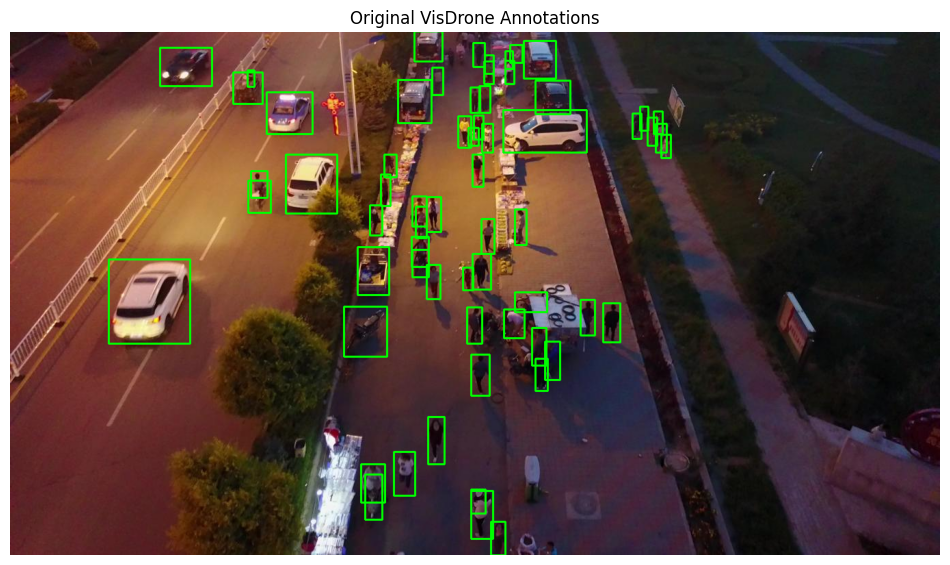

In [11]:
import cv2
import matplotlib.pyplot as plt

sample_image = os.path.join(
    RAW_DIR,
    "VisDrone2019-DET-train",
    "images",
    "0000072_07242_d_0000011.jpg"
)

image = cv2.imread(sample_image)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

with open(sample_ann, "r") as file:
    annotations = file.readlines()

for line in annotations:
    values = [int(x.strip()) for x in line.split(",")]

    x, y, w, h = values[:4]
    category = values[5]

    cv2.rectangle(
        image,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.axis("off")
plt.title("Original VisDrone Annotations")
plt.show()

In [12]:
import os

YOLO_DIR = "/content/VisDrone_Project/VisDrone_YOLO"

folders = [
    "images/train",
    "images/val",
    "labels/train",
    "labels/val"
]

for folder in folders:
    os.makedirs(os.path.join(YOLO_DIR, folder), exist_ok=True)

print("YOLO dataset folders created!")

YOLO dataset folders created!


In [13]:
import os
import cv2
import shutil
from tqdm import tqdm

# Original dataset folders
RAW_DIR = "/content/VisDrone_Project/raw"

# Destination YOLO dataset folder
YOLO_DIR = "/content/VisDrone_Project/VisDrone_YOLO"


def convert_dataset(split):

    image_dir = os.path.join(
        RAW_DIR,
        f"VisDrone2019-DET-{split}",
        "images"
    )

    annotation_dir = os.path.join(
        RAW_DIR,
        f"VisDrone2019-DET-{split}",
        "annotations"
    )

    output_image_dir = os.path.join(
        YOLO_DIR, "images", split
    )

    output_label_dir = os.path.join(
        YOLO_DIR, "labels", split
    )

    os.makedirs(output_image_dir, exist_ok=True)
    os.makedirs(output_label_dir, exist_ok=True)

    person_count = 0
    vehicle_count = 0
    image_count = 0

    image_files = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    for image_file in tqdm(image_files, desc=f"Converting {split}"):

        image_path = os.path.join(image_dir, image_file)

        annotation_file = os.path.splitext(image_file)[0] + ".txt"

        annotation_path = os.path.join(
            annotation_dir, annotation_file
        )

        # Read image dimensions
        image = cv2.imread(image_path)

        if image is None:
            continue

        image_height, image_width = image.shape[:2]

        yolo_annotations = []

        if os.path.exists(annotation_path):

            with open(annotation_path, "r") as file:

                for line in file:

                    values = line.strip().split(",")

                    if len(values) < 8:
                        continue

                    x, y, w, h = map(float, values[:4])
                    score = int(values[4])
                    category = int(values[5])

                    # Ignore invalid or ignored-region annotations
                    if score == 0:
                        continue

                    # Convert original categories into two classes
                    if category in [1, 2]:
                        class_id = 0
                        person_count += 1

                    elif category in [4, 5, 6, 7, 8, 9, 10]:
                        class_id = 1
                        vehicle_count += 1

                    else:
                        continue

                    # Clip bounding box to image boundaries
                    x1 = max(0, min(x, image_width))
                    y1 = max(0, min(y, image_height))
                    x2 = max(0, min(x + w, image_width))
                    y2 = max(0, min(y + h, image_height))

                    box_width = x2 - x1
                    box_height = y2 - y1

                    if box_width <= 0 or box_height <= 0:
                        continue

                    # Convert to YOLO normalized coordinates
                    x_center = ((x1 + x2) / 2) / image_width
                    y_center = ((y1 + y2) / 2) / image_height

                    normalized_width = box_width / image_width
                    normalized_height = box_height / image_height

                    yolo_line = (
                        f"{class_id} "
                        f"{x_center:.6f} "
                        f"{y_center:.6f} "
                        f"{normalized_width:.6f} "
                        f"{normalized_height:.6f}"
                    )

                    yolo_annotations.append(yolo_line)

        # Save converted annotation
        output_label_path = os.path.join(
            output_label_dir,
            os.path.splitext(image_file)[0] + ".txt"
        )

        with open(output_label_path, "w") as file:
            file.write("\n".join(yolo_annotations))

        # Copy original image
        shutil.copy2(
            image_path,
            os.path.join(output_image_dir, image_file)
        )

        image_count += 1

    print(f"\n{split.upper()} conversion completed")
    print("Images:", image_count)
    print("Person objects:", person_count)
    print("Vehicle objects:", vehicle_count)


# Convert training and validation datasets
convert_dataset("train")
convert_dataset("val")

Converting train: 100%|██████████| 6471/6471 [01:09<00:00, 93.52it/s]



TRAIN conversion completed
Images: 6471
Person objects: 106396
Vehicle objects: 226329


Converting val: 100%|██████████| 548/548 [00:04<00:00, 131.18it/s]


VAL conversion completed
Images: 548
Person objects: 13969
Vehicle objects: 23503


In [14]:
label_dir = os.path.join(YOLO_DIR, "labels", "train")

sample_files = os.listdir(label_dir)

print("Number of converted label files:", len(sample_files))

sample_file = os.path.join(label_dir, sample_files[0])

with open(sample_file, "r") as file:
    print("\nConverted YOLO annotations:")
    print(file.read()[:1000])

Number of converted label files: 6471

Converted YOLO annotations:
1 0.363214 0.096447 0.033571 0.040609
1 0.375357 0.315990 0.022143 0.060914
1 0.396429 0.223985 0.028571 0.057107
1 0.424643 0.374365 0.025000 0.065990
1 0.484643 0.663706 0.026429 0.096447
1 0.877857 0.276650 0.028571 0.078680
1 0.267500 0.068528 0.030714 0.038071
1 0.278571 0.032995 0.031429 0.032995
1 0.380714 0.013959 0.021429 0.027919
1 0.402857 0.013959 0.021429 0.027919
1 0.279286 0.125635 0.032857 0.043147
1 0.309286 0.070431 0.027143 0.044416
1 0.604643 0.744289 0.030714 0.123096
1 0.713571 0.636421 0.044286 0.133249
1 0.703929 0.307107 0.043571 0.157360
1 0.728214 0.080584 0.047857 0.161168
0 0.286071 0.345812 0.010714 0.021574
0 0.271071 0.340736 0.005000 0.013959
0 0.257500 0.244289 0.009286 0.024112
0 0.263929 0.241751 0.007857 0.029188


In [15]:
label_dir = os.path.join(YOLO_DIR, "labels", "train")

sample_file = os.path.join(label_dir, os.listdir(label_dir)[0])

with open(sample_file, "r") as file:
    for line in file:
        values = line.strip().split()
        print("Number of values:", len(values))
        print("Annotation:", values)

Number of values: 5
Annotation: ['1', '0.363214', '0.096447', '0.033571', '0.040609']
Number of values: 5
Annotation: ['1', '0.375357', '0.315990', '0.022143', '0.060914']
Number of values: 5
Annotation: ['1', '0.396429', '0.223985', '0.028571', '0.057107']
Number of values: 5
Annotation: ['1', '0.424643', '0.374365', '0.025000', '0.065990']
Number of values: 5
Annotation: ['1', '0.484643', '0.663706', '0.026429', '0.096447']
Number of values: 5
Annotation: ['1', '0.877857', '0.276650', '0.028571', '0.078680']
Number of values: 5
Annotation: ['1', '0.267500', '0.068528', '0.030714', '0.038071']
Number of values: 5
Annotation: ['1', '0.278571', '0.032995', '0.031429', '0.032995']
Number of values: 5
Annotation: ['1', '0.380714', '0.013959', '0.021429', '0.027919']
Number of values: 5
Annotation: ['1', '0.402857', '0.013959', '0.021429', '0.027919']
Number of values: 5
Annotation: ['1', '0.279286', '0.125635', '0.032857', '0.043147']
Number of values: 5
Annotation: ['1', '0.309286', '0.0

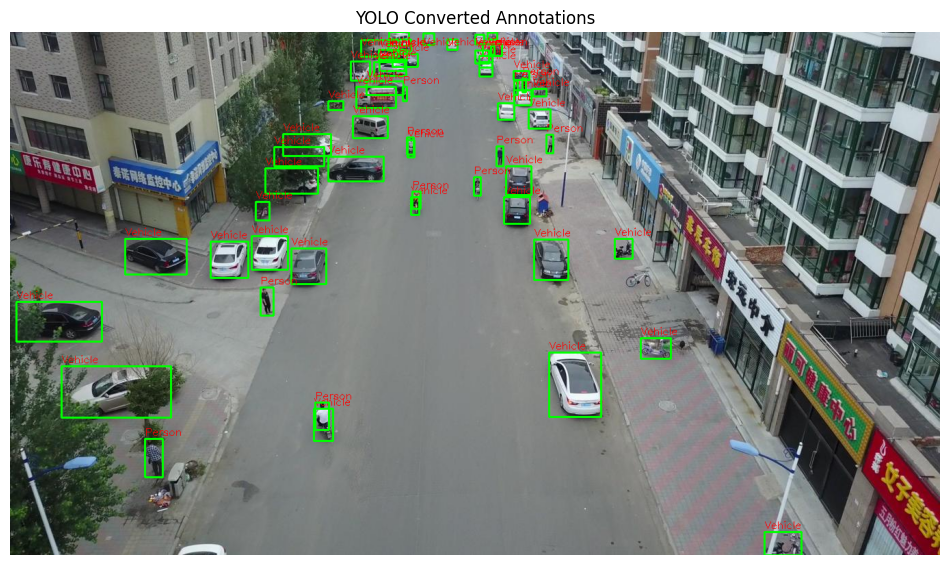

In [16]:
import cv2
import matplotlib.pyplot as plt
import os

image_dir = os.path.join(YOLO_DIR, "images", "train")
label_dir = os.path.join(YOLO_DIR, "labels", "train")

image_file = os.listdir(image_dir)[0]

image_path = os.path.join(image_dir, image_file)
label_path = os.path.join(
    label_dir,
    os.path.splitext(image_file)[0] + ".txt"
)

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]

with open(label_path, "r") as file:
    for line in file:
        class_id, xc, yc, w, h = map(float, line.split())

        # Convert normalized YOLO coordinates to pixels
        x1 = int((xc - w / 2) * width)
        y1 = int((yc - h / 2) * height)
        x2 = int((xc + w / 2) * width)
        y2 = int((yc + h / 2) * height)

        label = "Person" if int(class_id) == 0 else "Vehicle"

        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

        cv2.putText(
            image, label, (x1, max(20, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1
        )

plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.axis("off")
plt.title("YOLO Converted Annotations")
plt.show()

In [17]:
data_yaml = """
path: /content/VisDrone_Project/VisDrone_YOLO

train: images/train
val: images/val

nc: 2

names:
  0: Person
  1: Vehicle
"""

yaml_path = os.path.join(YOLO_DIR, "data.yaml")

with open(yaml_path, "w") as file:
    file.write(data_yaml)

print("data.yaml created successfully!")
print(data_yaml)

data.yaml created successfully!

path: /content/VisDrone_Project/VisDrone_YOLO

train: images/train
val: images/val

nc: 2

names:
  0: Person
  1: Vehicle



In [18]:
!pip install -q ultralytics

In [19]:
import torch
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.215
PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [20]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("YOLO11n loaded successfully!")

YOLO11n loaded successfully!


In [21]:
results = model.train(
    data=yaml_path,
    epochs=3,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project="/content/VisDrone_Project/runs",
    name="visdrone_pilot"
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/VisDrone_Project/VisDrone_YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=visdrone_pilot, nbs=64, nms=None, opset=

In [24]:
results = model.train(
    data=yaml_path,
    epochs=5,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project="/content/VisDrone_Project/runs",
    name="visdrone_pilot"
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/VisDrone_Project/VisDrone_YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/VisDrone_Project/runs/visdrone_pilot-3/weights/best.pt, momentum=0.937, mosaic=1.0, multi_sca

In [25]:
from ultralytics import YOLO

best_model = YOLO(
    "/content/VisDrone_Project/runs/visdrone_pilot-2/weights/best.pt"
)

test_results = best_model.predict(
    source="/content/VisDrone_Project/VisDrone_YOLO/images/val",
    conf=0.25,
    save=True,
    max_det=902
)

print("Prediction completed!")


image 1/548 /content/VisDrone_Project/VisDrone_YOLO/images/val/0000001_02999_d_0000005.jpg: 384x640 17 Persons, 32 Vehicles, 19.1ms
image 2/548 /content/VisDrone_Project/VisDrone_YOLO/images/val/0000001_03499_d_0000006.jpg: 384x640 17 Persons, 23 Vehicles, 65.0ms
image 3/548 /content/VisDrone_Project/VisDrone_YOLO/images/val/0000001_03999_d_0000007.jpg: 384x640 26 Persons, 7 Vehicles, 30.8ms
image 4/548 /content/VisDrone_Project/VisDrone_YOLO/images/val/0000001_04527_d_0000008.jpg: 384x640 43 Persons, 7 Vehicles, 41.6ms
image 5/548 /content/VisDrone_Project/VisDrone_YOLO/images/val/0000001_05249_d_0000009.jpg: 384x640 12 Persons, 105 Vehicles, 68.6ms
image 6/548 /content/VisDrone_Project/VisDrone_YOLO/images/val/0000001_05499_d_0000010.jpg: 384x640 6 Persons, 86 Vehicles, 55.3ms
image 7/548 /content/VisDrone_Project/VisDrone_YOLO/images/val/0000001_05999_d_0000011.jpg: 384x640 20 Persons, 44 Vehicles, 19.6ms
image 8/548 /content/VisDrone_Project/VisDrone_YOLO/images/val/0000001_07999_

In [26]:
from IPython.display import display, Image
import glob
import os

prediction_folder = (
    "/content/VisDrone_Project/runs/detect/predict"
)

prediction_images = glob.glob(
    os.path.join(prediction_folder, "*.jpg")
)

print("Predicted images:", len(prediction_images))

display(Image(filename=prediction_images[0]))

Predicted images: 0


IndexError: list index out of range

In [27]:
import os

base_folder = "/content/VisDrone_Project/runs"

for root, dirs, files in os.walk(base_folder):
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if image_files:
        print("Folder:", root)
        print("Number of images:", len(image_files))
        print("Example:", image_files[0])
        print("-" * 50)

Folder: /content/VisDrone_Project/runs/visdrone_pilot-4
Number of images: 17
Example: BoxPR_curve.png
--------------------------------------------------
Folder: /content/VisDrone_Project/runs/visdrone_pilot-2
Number of images: 17
Example: BoxPR_curve.png
--------------------------------------------------
Folder: /content/VisDrone_Project/runs/visdrone_pilot
Number of images: 17
Example: BoxPR_curve.png
--------------------------------------------------
Folder: /content/VisDrone_Project/runs/visdrone_pilot-3
Number of images: 17
Example: BoxPR_curve.png
--------------------------------------------------


In [28]:
from ultralytics import YOLO
import glob
import os

# Load your trained model
best_model = YOLO(
    "/content/VisDrone_Project/runs/visdrone_pilot-2/weights/best.pt"
)

# Select 5 validation images
image_paths = glob.glob(
    "/content/VisDrone_Project/VisDrone_YOLO/images/val/*.jpg"
)[:5]

print("Images selected:", len(image_paths))

# Generate predictions and save them
results = best_model.predict(
    source=image_paths,
    conf=0.25,
    save=True,
    max_det=902,
    project="/content/VisDrone_Project/runs/predictions",
    name="val_predictions",
    exist_ok=True
)

print("Prediction completed!")

Images selected: 5

0: 640x640 7 Persons, 52 Vehicles, 5.7ms
1: 640x640 20 Persons, 59 Vehicles, 5.7ms
2: 640x640 9 Persons, 26 Vehicles, 5.7ms
3: 640x640 18 Persons, 20 Vehicles, 5.7ms
4: 640x640 7 Persons, 49 Vehicles, 5.7ms
Speed: 2.4ms preprocess, 5.7ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/VisDrone_Project/runs/predictions/val_predictions
Prediction completed!


Predicted images: 5
0000277_04601_d_0000561.jpg


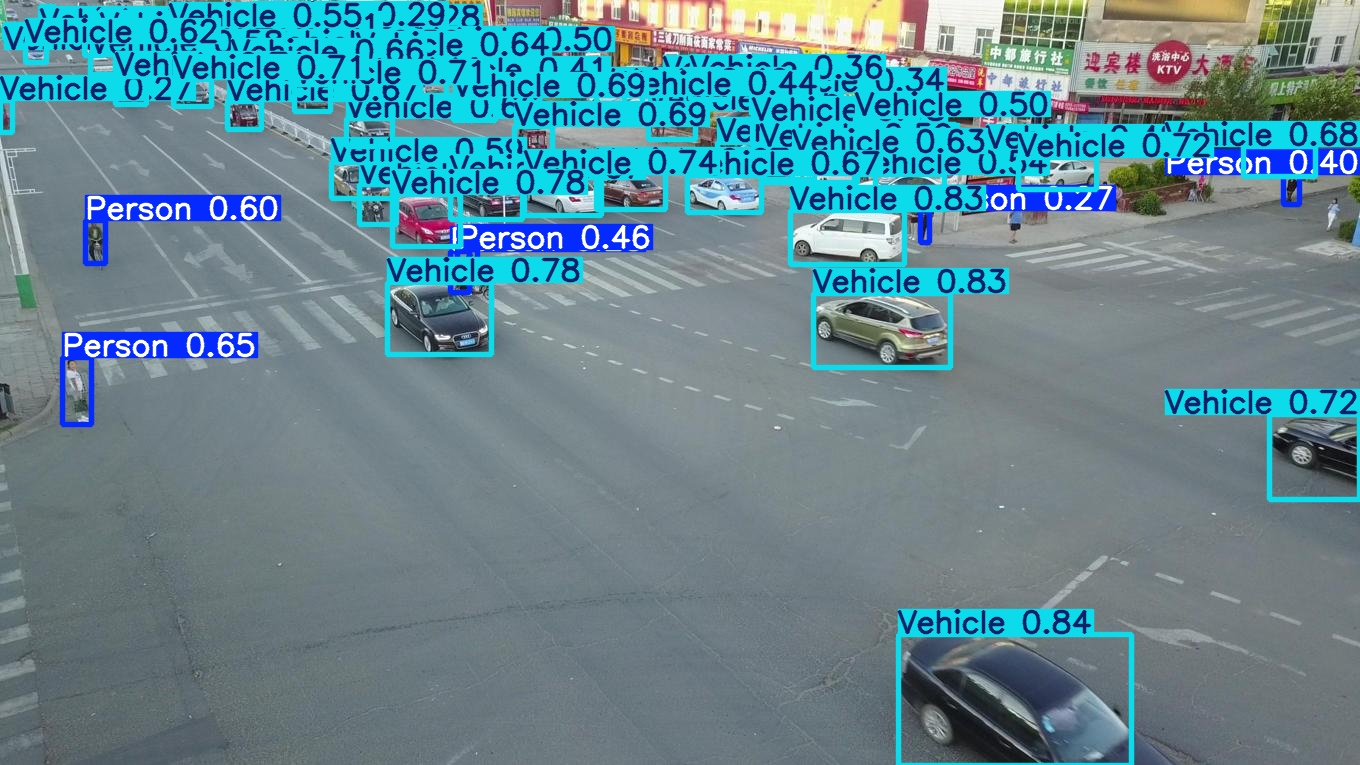

0000213_04998_d_0000245.jpg


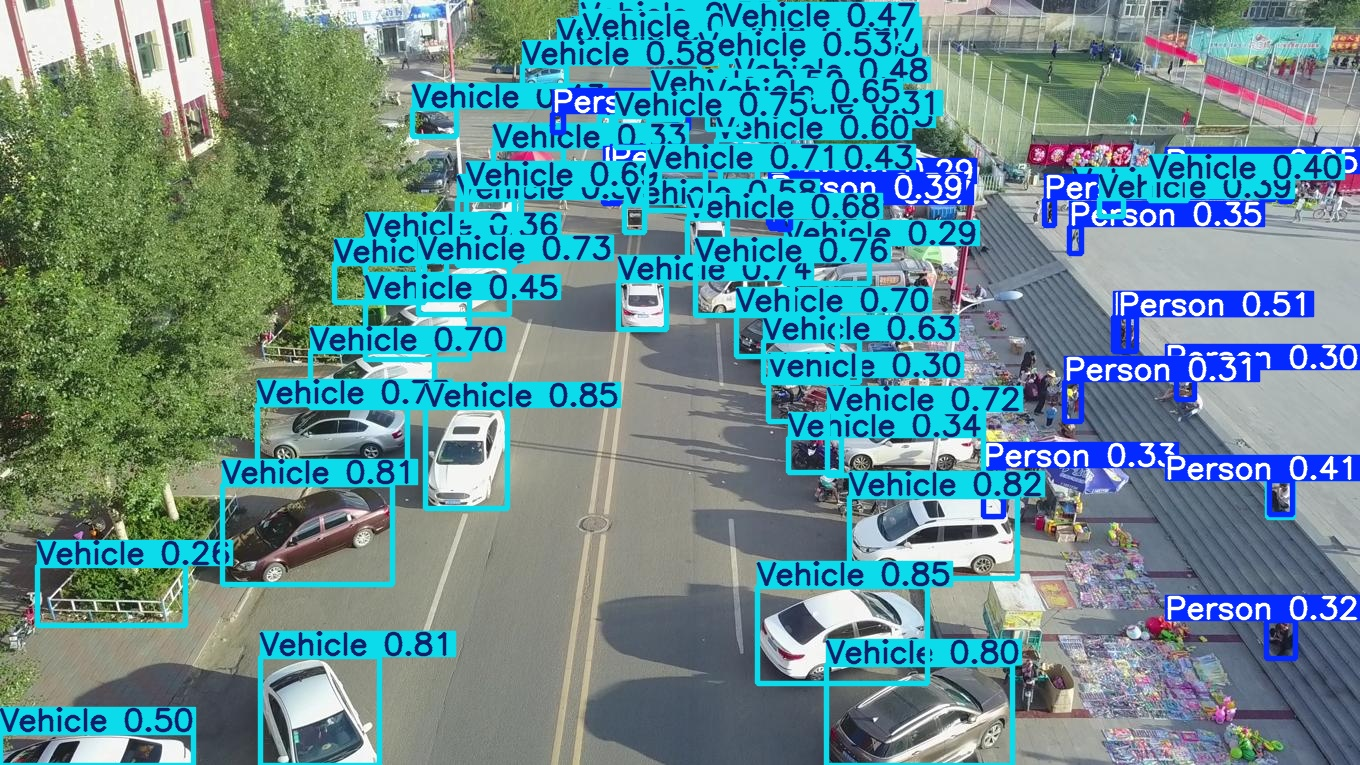

0000276_00001_d_0000507.jpg


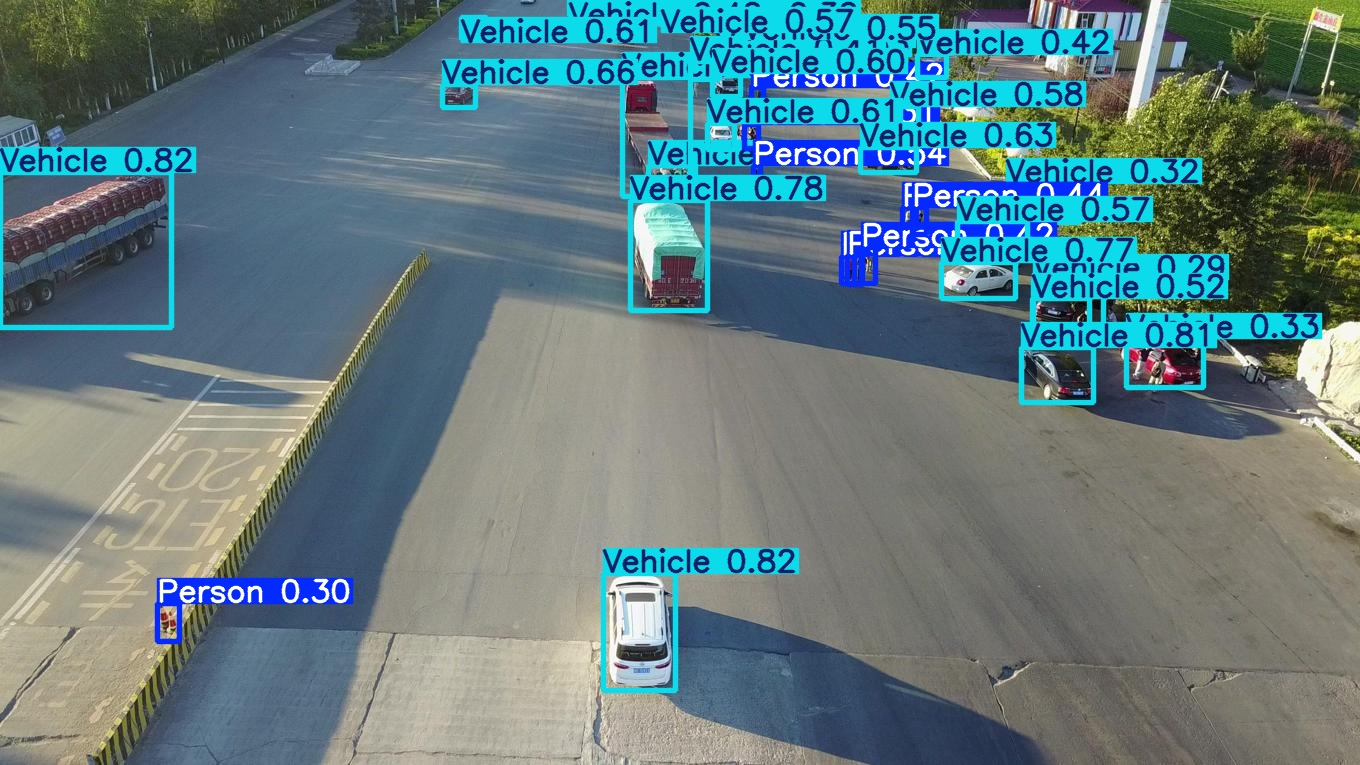

0000364_01177_d_0000799.jpg


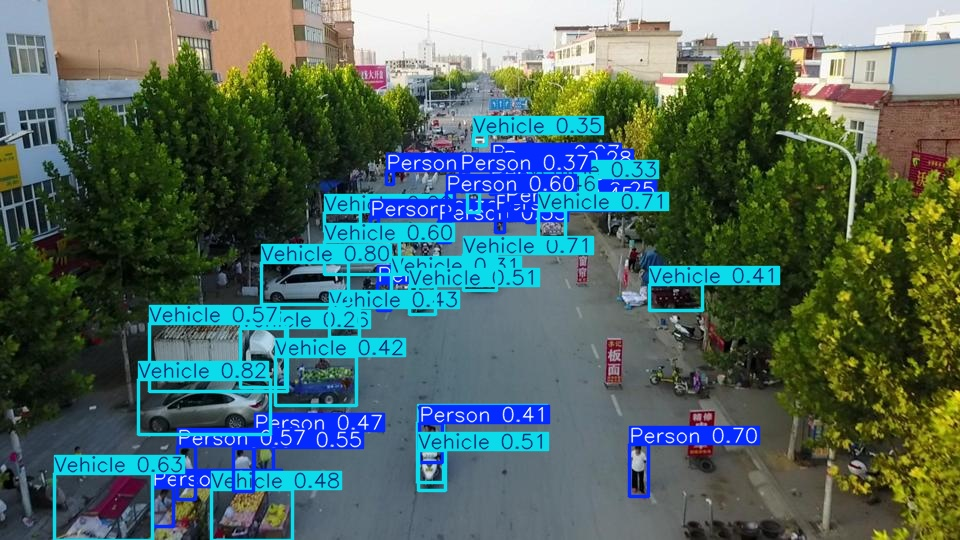

0000271_05401_d_0000399.jpg


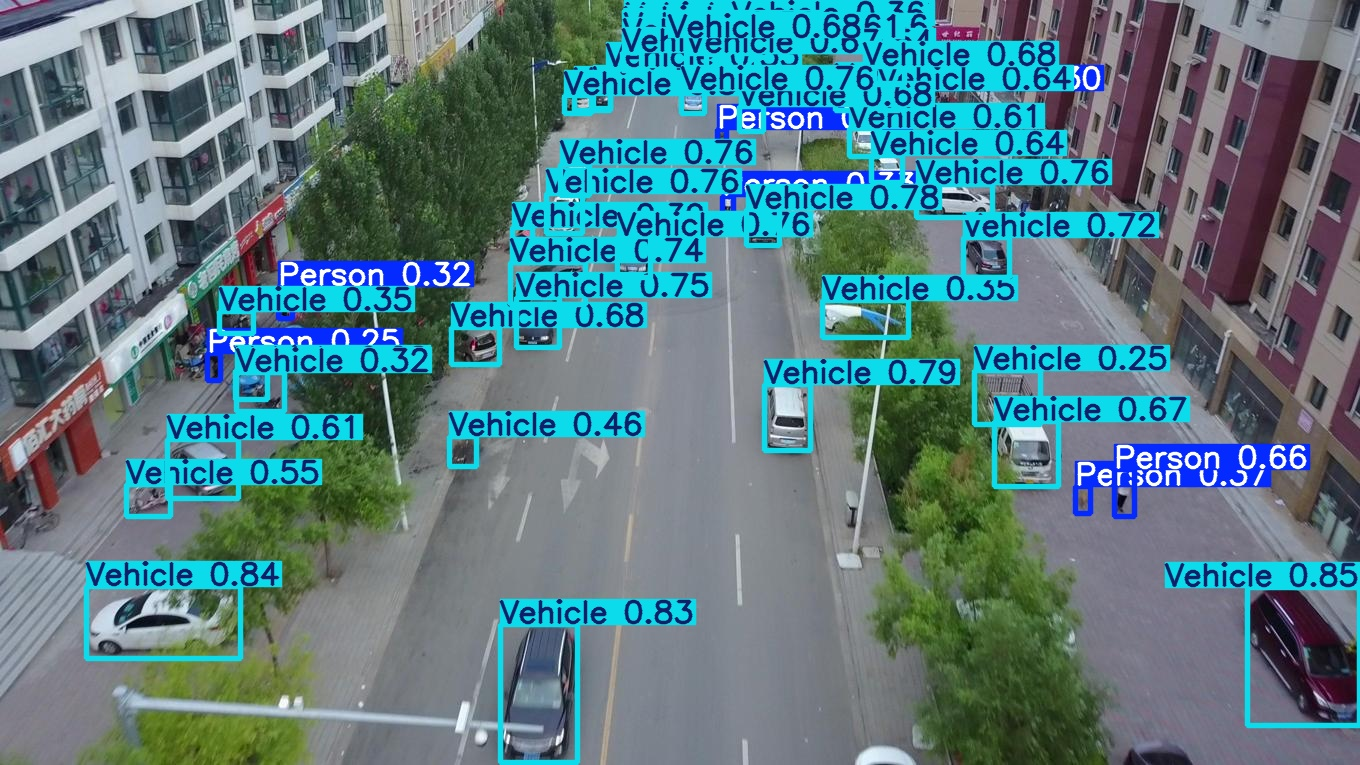

In [29]:
import glob
import os
from IPython.display import display, Image

prediction_folder = (
    "/content/VisDrone_Project/runs/predictions/val_predictions"
)

prediction_images = glob.glob(
    os.path.join(prediction_folder, "*.jpg")
)

print("Predicted images:", len(prediction_images))

for img_path in prediction_images:
    print(os.path.basename(img_path))
    display(Image(filename=img_path))

In [30]:
results = best_model.predict(
    source=image_paths[0],
    conf=0.40,
    save=True,
    max_det=300,
    project="/content/VisDrone_Project/runs/predictions",
    name="clear_predictions",
    exist_ok=True,
    line_width=2,
    show_labels=True,
    show_conf=True
)


image 1/1 /content/VisDrone_Project/VisDrone_YOLO/images/val/0000277_04601_d_0000561.jpg: 384x640 4 Persons, 39 Vehicles, 18.6ms
Speed: 2.9ms preprocess, 18.6ms inference, 3.6ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/VisDrone_Project/runs/predictions/clear_predictions


In [31]:
from IPython.display import display

display(results[0].plot())

array([[[157, 199, 114],
        [143, 184, 103],
        [175, 209, 138],
        ...,
        [198, 213, 216],
        [204, 216, 220],
        [206, 218, 222]],

       [[124, 166,  81],
        [121, 162,  81],
        [165, 199, 128],
        ...,
        [191, 206, 209],
        [197, 209, 213],
        [200, 212, 216]],

       [[131, 174,  87],
        [127, 169,  86],
        [161, 196, 122],
        ...,
        [190, 208, 209],
        [194, 209, 211],
        [197, 212, 214]],

       ...,

       [[108, 102,  89],
        [107, 101,  88],
        [105,  99,  86],
        ...,
        [116, 112, 107],
        [118, 114, 109],
        [121, 117, 112]],

       [[110, 104,  91],
        [108, 102,  89],
        [106, 100,  87],
        ...,
        [114, 110, 105],
        [118, 114, 109],
        [121, 117, 112]],

       [[109, 103,  90],
        [108, 102,  89],
        [106, 100,  87],
        ...,
        [113, 109, 104],
        [117, 113, 108],
        [121, 117, 112]]

In [32]:
import os

annotation_folder = (
    "/content/VisDrone_Project/raw/"
    "VisDrone2019-DET-train/annotations"
)

print("Original annotations folder exists:",
      os.path.exists(annotation_folder))

if os.path.exists(annotation_folder):
    files = os.listdir(annotation_folder)
    print("Number of annotation files:", len(files))
    print("First five files:", files[:5])

Original annotations folder exists: True
Number of annotation files: 6471
First five files: ['9999951_00000_d_0000094.txt', '9999962_00000_d_0000127.txt', '0000072_07242_d_0000011.txt', '9999990_00000_d_0000034.txt', '9999999_00073_d_0000023.txt']


In [33]:
import os
from collections import Counter

annotation_folder = (
    "/content/VisDrone_Project/raw/"
    "VisDrone2019-DET-train/annotations"
)

occlusion_counts = Counter()
person_count = 0

for filename in os.listdir(annotation_folder):

    if not filename.endswith(".txt"):
        continue

    filepath = os.path.join(annotation_folder, filename)

    with open(filepath, "r") as file:

        for line in file:

            values = line.strip().split(",")

            if len(values) != 8:
                continue

            score = int(values[4])
            category = int(values[5])
            occlusion = int(values[7])

            # Person categories: pedestrian and people
            if category in [1, 2] and score != 0:

                person_count += 1
                occlusion_counts[occlusion] += 1

print("Total person instances:", person_count)

for level in [0, 1, 2]:
    print(
        f"Occlusion level {level}: "
        f"{occlusion_counts[level]}"
    )

Total person instances: 106394
Occlusion level 0: 57202
Occlusion level 1: 41707
Occlusion level 2: 7485


In [34]:
from collections import Counter
import os

val_annotation_folder = (
    "/content/VisDrone_Project/raw/"
    "VisDrone2019-DET-val/annotations"
)

occlusion_counts = Counter()
total_persons = 0

for filename in os.listdir(val_annotation_folder):

    if not filename.endswith(".txt"):
        continue

    filepath = os.path.join(val_annotation_folder, filename)

    with open(filepath, "r") as file:
        for line in file:

            values = line.strip().split(",")

            if len(values) != 8:
                continue

            score = int(values[4])
            category = int(values[5])
            occlusion = int(values[7])

            if category in [1, 2] and score != 0:
                total_persons += 1
                occlusion_counts[occlusion] += 1

print("Validation person instances:", total_persons)

for level in [0, 1, 2]:
    print(
        f"Occlusion level {level}: "
        f"{occlusion_counts[level]}"
    )

Validation person instances: 13969
Occlusion level 0: 6337
Occlusion level 1: 6807
Occlusion level 2: 825


In [35]:
from ultralytics import YOLO
import os

# Load your trained model
model = YOLO(
    "/content/VisDrone_Project/runs/visdrone_pilot-2/weights/best.pt"
)

# Original validation annotations
annotation_folder = (
    "/content/VisDrone_Project/raw/"
    "VisDrone2019-DET-val/annotations"
)

# Validation images
image_folder = (
    "/content/VisDrone_Project/VisDrone_YOLO/images/val"
)

print("Model loaded successfully!")
print("Annotation files:", len(os.listdir(annotation_folder)))
print("Validation images:", len(os.listdir(image_folder)))

Model loaded successfully!
Annotation files: 548
Validation images: 548


In [36]:
def calculate_iou(box1, box2):

    # Get coordinates of intersection
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    # Intersection area
    intersection = (
        max(0, x2 - x1) *
        max(0, y2 - y1)
    )

    # Areas of both boxes
    area1 = (
        (box1[2] - box1[0]) *
        (box1[3] - box1[1])
    )

    area2 = (
        (box2[2] - box2[0]) *
        (box2[3] - box2[1])
    )

    # Union area
    union = area1 + area2 - intersection

    if union == 0:
        return 0

    return intersection / union

In [37]:
box_a = [10, 10, 50, 50]
box_b = [20, 20, 60, 60]

print("IoU:", calculate_iou(box_a, box_b))

IoU: 0.391304347826087


In [38]:
def match_predictions(predictions, ground_truths, iou_threshold=0.5):

    # Sort predictions by confidence, highest first
    predictions = sorted(
        predictions,
        key=lambda x: x["confidence"],
        reverse=True
    )

    # Track which ground-truth boxes have been matched
    matched_gt = set()

    # Store results for each occlusion level
    results = {
        0: {"TP": 0, "FN": 0},
        1: {"TP": 0, "FN": 0},
        2: {"TP": 0, "FN": 0}
    }

    false_positives = 0

    for prediction in predictions:

        best_iou = 0
        best_gt_index = -1

        for index, gt in enumerate(ground_truths):

            if index in matched_gt:
                continue

            iou = calculate_iou(
                prediction["box"],
                gt["box"]
            )

            if iou > best_iou:
                best_iou = iou
                best_gt_index = index

        # Check whether a valid match exists
        if best_iou >= iou_threshold:

            matched_gt.add(best_gt_index)

            occlusion = ground_truths[best_gt_index]["occlusion"]

            results[occlusion]["TP"] += 1

        else:
            false_positives += 1

    # Count unmatched ground-truth people as false negatives
    for index, gt in enumerate(ground_truths):

        if index not in matched_gt:

            results[gt["occlusion"]]["FN"] += 1

    return results, false_positives

In [39]:
ground_truths = [
    {
        "box": [10, 10, 50, 50],
        "occlusion": 0
    },
    {
        "box": [100, 100, 150, 150],
        "occlusion": 2
    }
]

predictions = [
    {
        "box": [12, 12, 48, 48],
        "confidence": 0.90
    },
    {
        "box": [200, 200, 240, 240],
        "confidence": 0.80
    }
]

results, fp = match_predictions(
    predictions,
    ground_truths
)

print("Matching results:", results)
print("False positives:", fp)

Matching results: {0: {'TP': 1, 'FN': 0}, 1: {'TP': 0, 'FN': 0}, 2: {'TP': 0, 'FN': 1}}
False positives: 1


In [40]:
import os
import glob
import numpy as np
from collections import defaultdict
from tqdm.notebook import tqdm
from ultralytics import YOLO

# 1. Load trained model
model = YOLO(
    "/content/VisDrone_Project/runs/visdrone_pilot-2/weights/best.pt"
)

image_folder = "/content/VisDrone_Project/VisDrone_YOLO/images/val"
annotation_folder = "/content/VisDrone_Project/raw/VisDrone2019-DET-val/annotations"

# 2. Evaluation settings
IOU_THRESHOLD = 0.5
CONF_THRESHOLD = 0.001

stats = {
    0: {"TP": 0, "FN": 0},
    1: {"TP": 0, "FN": 0},
    2: {"TP": 0, "FN": 0}
}
total_fp = 0

# 3. Load validation images
image_paths = sorted(glob.glob(os.path.join(image_folder, "*.jpg")))

# 4. Run YOLO predictions in batches
for start in tqdm(range(0, len(image_paths), 16)):

    batch = image_paths[start:start + 16]

    predictions = model.predict(
        source=batch,
        conf=CONF_THRESHOLD,
        imgsz=640,
        batch=16,
        device=0,
        max_det=902,
        verbose=False
    )

    for image_path, prediction in zip(batch, predictions):

        filename = os.path.splitext(os.path.basename(image_path))[0]
        annotation_path = os.path.join(annotation_folder, filename + ".txt")

        ground_truths = []

        # Read original VisDrone annotations
        with open(annotation_path, "r") as f:
            for line in f:

                values = line.strip().split(",")

                if len(values) != 8:
                    continue

                left, top, width, height = map(float, values[:4])
                score = int(values[4])
                category = int(values[5])
                occlusion = int(values[7])

                if category not in [1, 2] or score == 0:
                    continue

                ground_truths.append({
                    "box": [
                        left, top,
                        left + width, top + height
                    ],
                    "occlusion": occlusion
                })

        # Extract predicted person boxes (class 0)
        pred_boxes = prediction.boxes

        pred_indices = np.where(
            pred_boxes.cls.cpu().numpy() == 0
        )[0]

        pred_indices = sorted(
            pred_indices,
            key=lambda i: float(pred_boxes.conf[i]),
            reverse=True
        )

        predictions_list = []

        for i in pred_indices:
            predictions_list.append({
                "box": pred_boxes.xyxy[i].cpu().numpy().tolist(),
                "confidence": float(pred_boxes.conf[i])
            })

        # One-to-one matching
        matched_gt = set()

        for pred in predictions_list:

            best_iou = 0
            best_index = -1

            for j, gt in enumerate(ground_truths):

                if j in matched_gt:
                    continue

                iou = calculate_iou(pred["box"], gt["box"])

                if iou > best_iou:
                    best_iou = iou
                    best_index = j

            if best_iou >= IOU_THRESHOLD:

                matched_gt.add(best_index)
                level = ground_truths[best_index]["occlusion"]
                stats[level]["TP"] += 1

            else:
                total_fp += 1

        # Unmatched people are false negatives
        for j, gt in enumerate(ground_truths):
            if j not in matched_gt:
                stats[gt["occlusion"]]["FN"] += 1

# 5. Display results
print("\nOCCLUSION-WISE EVALUATION")
print("-" * 55)

for level in [0, 1, 2]:

    tp = stats[level]["TP"]
    fn = stats[level]["FN"]

    recall = tp / (tp + fn) if tp + fn else 0

    print(f"\nOcclusion Level {level}")
    print("True Positives:", tp)
    print("False Negatives:", fn)
    print(f"Recall: {recall:.4f} ({recall * 100:.2f}%)")

print("\nTotal person false positives:", total_fp)

  0%|          | 0/35 [00:00<?, ?it/s]


OCCLUSION-WISE EVALUATION
-------------------------------------------------------

Occlusion Level 0
True Positives: 3389
False Negatives: 2948
Recall: 0.5348 (53.48%)

Occlusion Level 1
True Positives: 3021
False Negatives: 3786
Recall: 0.4438 (44.38%)

Occlusion Level 2
True Positives: 253
False Negatives: 572
Recall: 0.3067 (30.67%)

Total person false positives: 98074


In [41]:
test_image = image_paths[0]

for threshold in [0.001, 0.25, 0.50]:
    result = model.predict(
        source=test_image,
        conf=threshold,
        device=0,
        verbose=False
    )[0]

    person_count = int((result.boxes.cls == 0).sum())

    print(
        f"Confidence: {threshold} | "
        f"Person detections: {person_count}"
    )



Confidence: 0.001 | Person detections: 167
Confidence: 0.25 | Person detections: 17
Confidence: 0.5 | Person detections: 0


In [42]:
import os
import shutil
import zipfile
from pathlib import Path

base = "/content/VisDrone_Project"
output = f"{base}/final_project_results"

os.makedirs(output, exist_ok=True)

# Copy trained model
model_path = f"{base}/runs/visdrone_pilot-2/weights/best.pt"

shutil.copy2(
    model_path,
    f"{output}/best.pt"
)

# Copy training graphs
for filename in [
    "results.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "confusion_matrix.png",
    "labels.jpg"
]:
    source = f"{base}/runs/visdrone_pilot-2/{filename}"

    if os.path.exists(source):
        shutil.copy2(source, output)

# Copy prediction images
prediction_folder = (
    f"{base}/runs/predictions/val_predictions"
)

if os.path.exists(prediction_folder):
    shutil.copytree(
        prediction_folder,
        f"{output}/predictions",
        dirs_exist_ok=True
    )

# Create ZIP
zip_path = f"{base}/Aerial_Object_Detection_Final.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(output):
        for file in files:
            path = os.path.join(root, file)
            z.write(path, os.path.relpath(path, output))

print("Project results collected successfully!")
print("ZIP:", zip_path)
print("Files:", os.listdir(output))

Project results collected successfully!
ZIP: /content/VisDrone_Project/Aerial_Object_Detection_Final.zip
Files: ['BoxPR_curve.png', 'predictions', 'BoxR_curve.png', 'BoxF1_curve.png', 'BoxP_curve.png', 'confusion_matrix.png', 'labels.jpg', 'results.png', 'best.pt']


In [43]:
from google.colab import files

files.download(
    "/content/VisDrone_Project/Aerial_Object_Detection_Final.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>